In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
from scipy.stats import linregress
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid
import pyreadr
import statistics as stats
import math
from tabulate import tabulate
from statsmodels.stats.contingency_tables import mcnemar

In [2]:
#load npz file
mixture_all_cycles = []

#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Mixture.npy.gz', "r")
mixture_all_cycles.append(np.float32(np.load(fn)))

for i in range(1, 2):
    print(i)
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_booldhsarr_basis_mixture_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
    cycle_np_file = np.load(filename)
    mixture_all_cycles.append(cycle_np_file['new_decomp_mixture'])

mixture_all_cycles = np.array(mixture_all_cycles)

1


In [3]:
n_components, n_DHSs = mixture_all_cycles[0].shape

In [5]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)

#top 10%
DHS_metadata['ind'] = DHS_metadata.index
DHS_metadata_sortby_mean_signal = DHS_metadata.sort_values(['mean_signal'], ascending=False)
top_10_percent_DHSs = DHS_metadata_sortby_mean_signal.iloc[:int(np.round(n_DHSs/10))]
top_10_percent_DHSs_inds = np.array(top_10_percent_DHSs['ind'])
top_10_percent_DHSs_identifiers = np.array(top_10_percent_DHSs['identifier'])

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [6]:
pickle_in = open('/home/ctrader/Hold/NMF/DHS/gene_DHSs_all_dict_CT20220324.pickle', 'rb')
gene_DHSs_all_dict=pickle.load(pickle_in)

In [7]:
comps_for_heatmap = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
comps_for_heatmap = np.array(comps_for_heatmap)

**Gene Enrichment**

In [8]:
#top comps
mixture_all_cycles_top_comp = np.argmax(mixture_all_cycles, axis=1)
# mixture_all_cycles_top_comp_val = np.max(mixture_all_cycles, axis=1)

# #sum
# mixture_all_cycles_sum = np.sum(mixture_all_cycles, axis=1)

In [9]:
# #expected enrichment
# mixture_cycle0_enrichment =[]
# mixture_cycle1_enrichment =[]
# for i in range(16):
#     mixture_cycle0_enrichment.append(len(np.where(mixture_all_cycles_top_comp[0, :]==i)[0])/n_DHSs)
#     mixture_cycle1_enrichment.append(len(np.where(mixture_all_cycles_top_comp[1, :]==i)[0])/n_DHSs)
# mixture_cycle0_enrichment = np.array(mixture_cycle0_enrichment)
# mixture_cycle1_enrichment = np.array(mixture_cycle1_enrichment)

In [12]:
# genes = np.array(list(gene_DHSs_all_dict.keys()))

# min_DHS_per_gene = []
# max_DHS_per_gene = []
# for gene in genes:
#     gene_arr = gene_DHSs_all_dict[gene]
#     if len(gene_arr)>0:
#         min_DHS_per_gene.append(np.min(gene_arr))
#         max_DHS_per_gene.append(np.max(gene_arr))
#     else:
#         min_DHS_per_gene.append(np.nan)
#         max_DHS_per_gene.append(np.nan)
# min_DHS_per_gene = np.array(min_DHS_per_gene)
# max_DHS_per_gene = np.array(max_DHS_per_gene)

In [13]:
# comp_differences = mixture_all_cycles_top_comp[0] - mixture_all_cycles_top_comp[1]
# DHS_with_comp_differences = np.where(np.abs(comp_differences)>0)[0]

In [14]:
# DHS_with_comp_differences.shape

(5767,)

In [15]:
# changed_comp_count_per_gene ={}
# for gene in genes:
#     changed_comp_count_per_gene[gene]=0
    
# for DHS in DHS_with_comp_differences:
#     if len(genes[(min_DHS_per_gene <= DHS) & (max_DHS_per_gene >= DHS)]) > 0:
#         gene_list = genes[(min_DHS_per_gene <= DHS) & (max_DHS_per_gene >= DHS)]
#         for gene in gene_list:
#             changed_comp_count_per_gene[gene]+=1

In [16]:
# changed_comp_count_per_gene_values = np.array(list(changed_comp_count_per_gene.values()))
# changed_comp_count_per_gene_keys = np.array(list(changed_comp_count_per_gene.keys()))

In [17]:
# top_changed_genes = changed_comp_count_per_gene_keys[np.argsort(-changed_comp_count_per_gene_values)]

In [18]:
# #number of genes where there are more counts of enriched DHS after flipping
# count = 0
# for g in top_changed_genes:
#     if len(gene_DHSs_all_dict[g]) > 0:
#         original_mode = stats.mode(mixture_all_cycles_top_comp[0, gene_DHSs_all_dict[g]])
#         new_mode = stats.mode(mixture_all_cycles_top_comp[1, gene_DHSs_all_dict[g]])
#         if original_mode==new_mode:
#             original_mode_len = len(np.where(mixture_all_cycles_top_comp[0, gene_DHSs_all_dict[g]]==original_mode)[0])
#             new_mode_len = len(np.where(mixture_all_cycles_top_comp[1, gene_DHSs_all_dict[g]]==original_mode)[0])
#             if new_mode_len > original_mode_len:
#                 count+=1
# print(count)

668


In [45]:
# for g in top_changed_genes[:20]:
#     original_mode = stats.mode(mixture_all_cycles_top_comp[0, gene_DHSs_all_dict[g]])
#     new_mode = stats.mode(mixture_all_cycles_top_comp[1, gene_DHSs_all_dict[g]])
#     if original_mode==new_mode:
#         print(g)
#         print(comps_for_heatmap[original_mode])
#         original_num_of_mode = len(np.where(mixture_all_cycles_top_comp[0, gene_DHSs_all_dict[g]]==original_mode)[0])
#         new_num_of_mode = len(np.where(mixture_all_cycles_top_comp[1, gene_DHSs_all_dict[g]]==original_mode)[0])
#         print(original_num_of_mode)
#         print(new_num_of_mode)
#         print(np.log2((original_num_of_mode/len(gene_DHSs_all_dict[g])) / mixture_cycle0_enrichment[original_mode]))
#         print(np.log2((new_num_of_mode/len(gene_DHSs_all_dict[g])) / mixture_cycle1_enrichment[original_mode]))
#         print()

AC010091.1
Stromal B
70
70
1.2286038752640487
1.2306006705222918

ITPR1
Primitive / embryonic
112
117
-0.01989325477993866
0.041668912060865156

`RP11-36B6.2`
Stromal B
160
161
1.0895545514724212
1.100540129957919

EYS
Neural
320
321
0.6861509436926008
0.6901334719434333

ZNF438
Stromal B
63
63
0.9565243298272479
0.958521125085491

PARK2
Neural
340
339
0.6956112729416672
0.690842935956201

CUL9
Primitive / embryonic
43
49
1.3308204669149823
1.5178179256430961

`RP11-9J18.1`
Stromal B
274
272
0.6669429232303826
0.6583704767784386

FEZ2
Vascular / endothelial
19
19
3.0670610518612875
3.0651234759110695

ARMC4
Neural
23
23
0.09165713822790152
0.09113827424379348

C10orf11
Primitive / embryonic
252
253
-0.21770003783811354
-0.21343401732871647

SGIP1
Stromal B
57
57
0.5940421365892508
0.5960389318474938

`LINC-PINT`
Lymphoid
83
83
1.5714823663251267
1.5708234510175372

STC1
Stromal B
10
10
0.9792444063273313
0.9812412015855745

DLG2
Neural
462
462
0.7541699236065305
0.7536510596224223

MAS

In [43]:
# for i in range(20):
#     g = top_changed_genes[i]
#     original_mode = stats.mode(mixture_all_cycles_top_comp[0, gene_DHSs_all_dict[g]])
#     new_mode = stats.mode(mixture_all_cycles_top_comp[1, gene_DHSs_all_dict[g]])
#     print(g)
#     print(comps_for_heatmap[original_mode])
#     print(comps_for_heatmap[new_mode])
#     print()
#     print((len(np.where(mixture_all_cycles_top_comp[0, gene_DHSs_all_dict[g]]==original_mode)[0])/len(gene_DHSs_all_dict[g])) / mixture_cycle0_enrichment[original_mode])
#     print((len(np.where(mixture_all_cycles_top_comp[0, gene_DHSs_all_dict[g]]==new_mode)[0])/len(gene_DHSs_all_dict[g])) / mixture_cycle0_enrichment[new_mode])
#     print()
#     print((len(np.where(mixture_all_cycles_top_comp[1, gene_DHSs_all_dict[g]]==original_mode)[0])/len(gene_DHSs_all_dict[g])) / mixture_cycle0_enrichment[original_mode])
#     print((len(np.where(mixture_all_cycles_top_comp[1, gene_DHSs_all_dict[g]]==new_mode)[0])/len(gene_DHSs_all_dict[g])) / mixture_cycle0_enrichment[new_mode])
#     print()
#     print()

RADIL
Organ devel. / renal
Primitive / embryonic

6.3717474573456645
1.2892171416223146

4.967803102337299
1.645809116964657


AC010091.1
Stromal B
Stromal B

2.343401044951304
2.343401044951304

2.343401044951304
2.343401044951304


ITPR1
Primitive / embryonic
Primitive / embryonic

0.9863056786970992
0.9863056786970992

1.0303371822103624
1.0303371822103624


`RP11-36B6.2`
Stromal B
Stromal B

2.12808319353042
2.12808319353042

2.1413837134899847
2.1413837134899847


EYS
Neural
Neural

1.6089850750637824
1.6089850750637824

1.6140131534233568
1.6140131534233568


ZNF438
Stromal B
Stromal B

1.9406289903502987
1.9406289903502987

1.9406289903502987
1.9406289903502987


PARK2
Neural
Neural

1.6195705031892023
1.6195705031892023

1.6148070605327633
1.6148070605327633


CUL9
Primitive / embryonic
Primitive / embryonic

2.5154568935648594
2.5154568935648594

2.866450878713444
2.866450878713444


`RP11-9J18.1`
Stromal B
Stromal B

1.58770504687799
1.58770504687799

1.5761159589445741
1.576

In [9]:
comp_enrichment_difference_from_original = []
for gene_ind in range(len(comp_enrichment_for_each_gene[0, :, 0])):
    original_max_comp = np.argmax(comp_enrichment_for_each_gene[0, gene_ind, :])
    original_max_comp_val = comp_enrichment_for_each_gene[0, gene_ind, original_max_comp]
    new_original_max_comp_val = comp_enrichment_for_each_gene[1, gene_ind, original_max_comp]
    comp_enrichment_difference_from_original.append(new_original_max_comp_val - original_max_comp_val)
    
comp_enrichment_difference_from_original = np.array(comp_enrichment_difference_from_original)

NameError: name 'comp_enrichment_for_each_gene' is not defined

In [ ]:
comp_enrichment_difference_from_original_filtered = comp_enrichment_difference_from_original[(~np.isinf(comp_enrichment_difference_from_original)) &
                                                                                             (~np.isnan(comp_enrichment_difference_from_original))]

Text(0.5, 1, 'Enrichment Increase of Originally Most Enriched Component of Each Gene\nReconstruction Threshold Flip, Threshold=0.0/1.0')

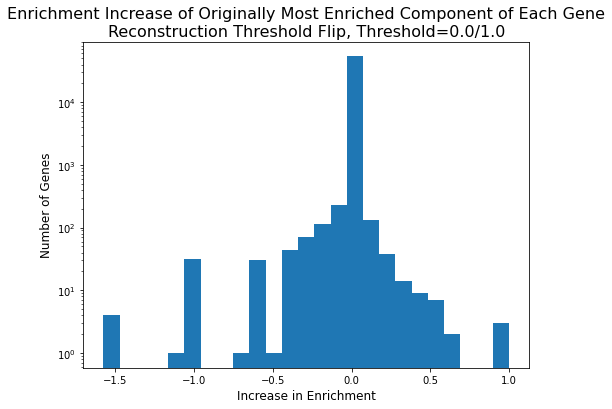

In [127]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

plt.hist(comp_enrichment_difference_from_original_filtered, bins=25)
plt.yscale('log')

plt.xlabel('Increase in Enrichment', fontsize=12)
plt.ylabel('Number of Genes', fontsize=12)
plt.title('Enrichment Increase of Originally Most Enriched Component of Each Gene\nReconstruction Threshold Flip, Threshold=0.0/1.0', fontsize=16, x=0.5, y=1)

In [ ]:
comp_enrichment_difference_from_new = []
for gene_ind in range(len(comp_enrichment_for_each_gene[0, :, 0])):
    new_max_comp = np.argmax(comp_enrichment_for_each_gene[1, gene_ind, :])
    new_max_comp_val = comp_enrichment_for_each_gene[1, gene_ind, new_max_comp]
    original_new_max_comp_val = comp_enrichment_for_each_gene[0, gene_ind, new_max_comp]
    comp_enrichment_difference_from_new.append(new_max_comp_val - original_new_max_comp_val)
    
comp_enrichment_difference_from_new = np.array(comp_enrichment_difference_from_new)

In [ ]:
comp_enrichment_difference_from_new_filtered = comp_enrichment_difference_from_new[(~np.isinf(comp_enrichment_difference_from_new)) &
                                                                                   (~np.isnan(comp_enrichment_difference_from_new))]

Text(0.5, 1, 'Enrichment Increase of Newly Most Enriched Component of Each Gene\nReconstruction Threshold Flip, Threshold=0.0/1.0')

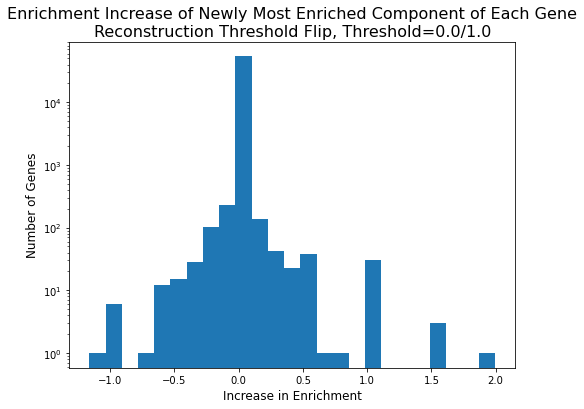

In [133]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

plt.hist(comp_enrichment_difference_from_new_filtered, bins=25)
plt.yscale('log')

plt.xlabel('Increase in Enrichment', fontsize=12)
plt.ylabel('Number of Genes', fontsize=12)
plt.title('Enrichment Increase of Newly Most Enriched Component of Each Gene\nReconstruction Threshold Flip, Threshold=0.0/1.0', fontsize=16, x=0.5, y=1)

In [ ]:
comp_enrichment_diff_in_max_vals = []
for gene_ind in range(len(comp_enrichment_for_each_gene[0, :, 0])):
    
    new_max_comp = np.argmax(comp_enrichment_for_each_gene[1, gene_ind, :])
    new_max_comp_val = comp_enrichment_for_each_gene[1, gene_ind, new_max_comp]
    
    original_max_comp = np.argmax(comp_enrichment_for_each_gene[0, gene_ind, :])
    original_max_comp_val = comp_enrichment_for_each_gene[0, gene_ind, original_max_comp]
    
    comp_enrichment_diff_in_max_vals.append(new_max_comp_val - original_max_comp_val)
    
comp_enrichment_diff_in_max_vals = np.array(comp_enrichment_diff_in_max_vals)

In [ ]:
comp_enrichment_diff_in_max_vals_filtered = comp_enrichment_diff_in_max_vals[(~np.isinf(comp_enrichment_diff_in_max_vals)) &
                                                                             (~np.isnan(comp_enrichment_diff_in_max_vals))]

Text(0.5, 1, 'Increase in Max Enrichment Value for Each Gene\nReconstruction Threshold Flip, Threshold=0.0/1.0')

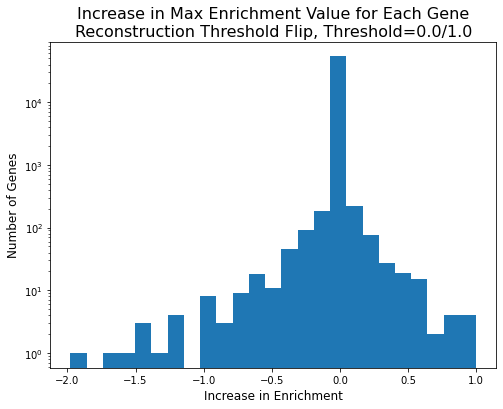

In [152]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

plt.hist(comp_enrichment_diff_in_max_vals_filtered, bins=25)
plt.yscale('log')

plt.xlabel('Increase in Enrichment', fontsize=12)
plt.ylabel('Number of Genes', fontsize=12)
plt.title('Increase in Max Enrichment Value for Each Gene\nReconstruction Threshold Flip, Threshold=0.0/1.0', fontsize=16, x=0.5, y=1)

In [10]:
def gene_enrichment(gene, cycle):
    gene_ind = np.where(genes==gene)[0][0]
    enrichment = comp_enrichment_for_each_gene[cycle, gene_ind, :]
    return enrichment

def change_in_enrichment(gene):
#     change = gene_enrichment(gene, 1) - gene_enrichment(gene, 0)
    print(gene)
    print('Originally Enriched Components = %s' %(comps_for_heatmap[np.where(gene_enrichment(gene, 0)>0)]))
    print('Originally Most Enriched Component = %s (%s)' %(comps_for_heatmap[np.argmax(gene_enrichment(gene, 0))], np.max(gene_enrichment(gene, 0))))
    
    print('Newly Most Enriched Components = %s' %(comps_for_heatmap[np.where(gene_enrichment(gene, 1)>0)]))
    print('Newly Most Enriched Component = %s (%s)' %(comps_for_heatmap[np.argmax(gene_enrichment(gene, 1))], np.max(gene_enrichment(gene, 1))))
    print()
    return

In [189]:
change_in_enrichment('GATA1')
change_in_enrichment('FOXP3')
change_in_enrichment('HOXB9')
change_in_enrichment('CDX2')

GATA1
Originally Enriched Components = ['Stromal A' 'Myeloid / erythroid']
Originally Most Enriched Component = Myeloid / erythroid (3.814089587647749)
Newly Most Enriched Components = ['Stromal A' 'Myeloid / erythroid']
Newly Most Enriched Component = Myeloid / erythroid (3.814128242274584)

FOXP3
Originally Enriched Components = ['Lymphoid' 'Digestive']
Originally Most Enriched Component = Lymphoid (3.345839673171899)
Newly Most Enriched Components = ['Lymphoid' 'Digestive']
Newly Most Enriched Component = Lymphoid (3.3451807578643096)

HOXB9
Originally Enriched Components = ['Tissue invariant' 'Primitive / embryonic' 'Renal / cancer'
 'Organ devel. / renal']
Originally Most Enriched Component = Organ devel. / renal (3.689050247792201)
Newly Most Enriched Components = ['Tissue invariant' 'Primitive / embryonic' 'Renal / cancer'
 'Organ devel. / renal']
Newly Most Enriched Component = Organ devel. / renal (3.696585391881568)

CDX2
Originally Enriched Components = ['Primitive / embryon

In [190]:
change_in_enrichment('RADIL')

RADIL
Originally Enriched Components = ['Primitive / embryonic' 'Placental / trophoblast' 'Cardiac'
 'Organ devel. / renal' 'Pulmonary devel.' 'Vascular / endothelial']
Originally Most Enriched Component = Organ devel. / renal (2.6716890871307633)
Newly Most Enriched Components = ['Primitive / embryonic' 'Placental / trophoblast' 'Cardiac'
 'Organ devel. / renal' 'Pulmonary devel.' 'Vascular / endothelial']
Newly Most Enriched Component = Organ devel. / renal (2.3201431379153026)



**Number of genes that switch top components**

In [105]:
gene_DHSs_all_dict[gene]

array([3591822, 3591823, 3591824, 3591825, 3591826, 3591827, 3591828,
       3591829, 3591830, 3591831, 3591832, 3591833, 3591834, 3591835,
       3591836])

In [13]:
genes = np.array(list(gene_DHSs_all_dict.keys()))

DHSs_in_a_gene = np.array([], dtype=int)
for gene in genes:
    DHSs_in_a_gene = np.append(DHSs_in_a_gene, gene_DHSs_all_dict[gene])
DHSs_in_a_gene = np.unique(DHSs_in_a_gene)

In [14]:
#real expected enrichment
mixture_cycle0_enrichment =[]
mixture_cycle1_enrichment =[]
for i in range(16):
    mixture_cycle0_enrichment.append(len(np.where(mixture_all_cycles_top_comp[0, DHSs_in_a_gene]==i)[0])/len(DHSs_in_a_gene))
    mixture_cycle1_enrichment.append(len(np.where(mixture_all_cycles_top_comp[1, DHSs_in_a_gene]==i)[0])/len(DHSs_in_a_gene))
mixture_cycle0_enrichment = np.array(mixture_cycle0_enrichment)
mixture_cycle1_enrichment = np.array(mixture_cycle1_enrichment)

In [15]:
#finding the counts of each component in each gene


original_comp_counts_for_each_gene = []
for gene in genes:
    dhss_in_gene = gene_DHSs_all_dict[gene]
    comps_in_gene = mixture_all_cycles_top_comp[0, dhss_in_gene]
    gene_comp_counts = []
    for comp in range(16):
        gene_comp_counts.append(len(np.where(comps_in_gene==comp)[0]))
    original_comp_counts_for_each_gene.append(gene_comp_counts)
original_comp_counts_for_each_gene = np.array(original_comp_counts_for_each_gene)

new_comp_counts_for_each_gene = []
for gene in genes:
    dhss_in_gene = gene_DHSs_all_dict[gene]
    comps_in_gene = mixture_all_cycles_top_comp[1, dhss_in_gene]
    gene_comp_counts = []
    for comp in range(16):
        gene_comp_counts.append(len(np.where(comps_in_gene==comp)[0]))
    new_comp_counts_for_each_gene.append(gene_comp_counts)
new_comp_counts_for_each_gene = np.array(new_comp_counts_for_each_gene)

# comp_counts_for_each_gene = np.array([original_comp_counts_for_each_gene, new_comp_counts_for_each_gene])

DHS_nums_in_each_gene = []
for gene in genes:
    DHS_nums_in_each_gene.append(len(gene_DHSs_all_dict[gene]))
DHS_nums_in_each_gene = np.array(DHS_nums_in_each_gene)

# #enrichment of each gene
# original_comp_enrichment_for_each_gene = np.log2((original_comp_counts_for_each_gene.T/DHS_nums_in_each_gene).T/mixture_cycle0_enrichment)
# new_comp_enrichment_for_each_gene = np.log2((new_comp_counts_for_each_gene.T/DHS_nums_in_each_gene).T/mixture_cycle1_enrichment)

#test - delete
original_comp_enrichment_for_each_gene = ((original_comp_counts_for_each_gene.T/DHS_nums_in_each_gene).T/mixture_cycle0_enrichment)
new_comp_enrichment_for_each_gene = ((new_comp_counts_for_each_gene.T/DHS_nums_in_each_gene).T/mixture_cycle1_enrichment)


comp_enrichment_for_each_gene = np.array([original_comp_enrichment_for_each_gene, new_comp_enrichment_for_each_gene])

/tmp/ipykernel_66580/1788572194.py:36: RuntimeWarning: invalid value encountered in true_divide
  original_comp_enrichment_for_each_gene = ((original_comp_counts_for_each_gene.T/DHS_nums_in_each_gene).T/mixture_cycle0_enrichment)
/tmp/ipykernel_66580/1788572194.py:37: RuntimeWarning: invalid value encountered in true_divide
  new_comp_enrichment_for_each_gene = ((new_comp_counts_for_each_gene.T/DHS_nums_in_each_gene).T/mixture_cycle1_enrichment)


In [16]:
#finding top enriched comp of each gene
top_enriched_comp_each_gene = np.argmax(comp_enrichment_for_each_gene, axis=2).astype(float)
#setting all nan genes to nan
for i in range(len(comp_enrichment_for_each_gene[0, :, 0])):
    if len(comp_enrichment_for_each_gene[0, i, :][np.isnan(comp_enrichment_for_each_gene[0, i, :])]) == 16:
        top_enriched_comp_each_gene[0, i]=np.nan
    if len(comp_enrichment_for_each_gene[1, i, :][np.isnan(comp_enrichment_for_each_gene[1, i, :])]) == 16:
        top_enriched_comp_each_gene[1, i]=np.nan 

In [17]:
#number of genes that have change in top enriched component
genes_with_top_enriched_comp_change = (np.where(((top_enriched_comp_each_gene[0]!=top_enriched_comp_each_gene[1]) & 
                                                 (~np.isnan(top_enriched_comp_each_gene[0])) & 
                                                 (~np.isnan(top_enriched_comp_each_gene[1]))))[0])
len(genes_with_top_enriched_comp_change)

330

In [194]:
mixture_cycle0_enrichment

array([0.04389601, 0.01564243, 0.17443173, 0.11272119, 0.07800667,
       0.04011445, 0.07377158, 0.12847748, 0.03309365, 0.04430443,
       0.02682955, 0.06038423, 0.04027982, 0.02361593, 0.0519547 ,
       0.05247616])

In [199]:
np.log2((original_comp_counts_for_each_gene[20:22, :].T/DHS_nums_in_each_gene[20:22]).T/mixture_cycle0_enrichment)

/tmp/ipykernel_88157/290271.py:1: RuntimeWarning: divide by zero encountered in log2
  np.log2((original_comp_counts_for_each_gene[20:22, :].T/DHS_nums_in_each_gene[20:22]).T/mixture_cycle0_enrichment)


array([[      -inf,       -inf, 1.51926556,       -inf,       -inf,
              -inf,       -inf, 1.3754501 ,       -inf,       -inf,
              -inf,       -inf,       -inf,       -inf,       -inf,
        1.66723164],
       [1.33984129,       -inf, 0.34934055,       -inf,       -inf,
              -inf, 1.590866  ,       -inf,       -inf,       -inf,
              -inf,       -inf, 1.463874  ,       -inf,       -inf,
        2.66723164]])

In [22]:
top_enriched_comp_each_gene

array([[nan,  0., nan, ..., 13., nan,  4.],
       [nan,  0., nan, ..., 13., nan,  4.]])

In [18]:
#gene enrichments from paper
known_gene_enrichments = pd.read_excel('/home/ctrader/NMF_data/gene_enrichment/41586_2020_2559_MOESM4_ESM.xlsx', sheet_name=None)

In [19]:
comp_keys = np.array(list(known_gene_enrichments.keys()))
paper2NMF_comp_order = [6, 2, 9, 10, 4, 14, 8, 11, 13, 7, 12, 5, 15, 1, 3, 0]

In [161]:
comp_keys

array(['Placental & trophoblast', 'Primitive & embryonic',
       'Organ devel. & renal', 'Pulmonary devel.', 'Lymphoid',
       'Myeloid & erythroid', 'Cardiac', 'Musculoskeletal',
       'Vascular & endothelial', 'Neural', 'Digestive', 'Renal & cancer',
       'Cancer & epithelial', 'Stromal A', 'Stromal B',
       'Tissue invariant'], dtype='<U23')

In [116]:
np.where(np.array(genes=='MIR137HG'))[0]

array([2254])

In [20]:
#checking enrichment results with what is in paper
paper_gene_enriched_comps = np.zeros(len(genes))*np.nan
c=0
gene_counts = np.zeros(len(genes))
for key, i in zip(comp_keys, paper2NMF_comp_order):
    genes_in_comp_known = np.array(known_gene_enrichments[key]['name'])
    for gene in genes_in_comp_known:
        gene_ind_list = np.where(genes==gene)[0]
        if len(gene_ind_list) > 0:
            gene_ind = gene_ind_list[0]
            paper_gene_enriched_comps[gene_ind]=i
            gene_counts[gene_ind]+=1
        
            gene_comp = top_enriched_comp_each_gene[0, gene_ind]
            if gene_comp!=i:
                c+=1

In [185]:
DHS_metadata.loc[[12012]]

,seqname,start,end,identifier,mean_signal,numsamples,summit,core_start,core_end,component,ind
12012,chr1,7051180,7051411,1.125418,0.527066,28,7051300,7051184,7051330,Neural,12012


In [182]:
c

1425

In [26]:
np.where(~np.isnan(paper_calc_diff))[0].shape

(13421,)

In [21]:
paper_calc_diff = paper_gene_enriched_comps - top_enriched_comp_each_gene[0]

In [22]:
gene_inds_with_paper_calc_comp_diff = np.where((paper_calc_diff!=0) & (~np.isnan(paper_calc_diff)))[0]

In [27]:
gene_inds_with_paper_calc_comp_diff.shape

(1425,)

In [151]:
len(gene_inds_with_paper_calc_comp_diff)

1425

In [25]:
j=1000
print(genes[gene_inds_with_paper_calc_comp_diff[j]])
print(int(top_enriched_comp_each_gene[0][gene_inds_with_paper_calc_comp_diff[j]]), comps_for_heatmap[int(top_enriched_comp_each_gene[0][gene_inds_with_paper_calc_comp_diff[j]])])
print(int(paper_gene_enriched_comps[gene_inds_with_paper_calc_comp_diff[j]]), comps_for_heatmap[int(paper_gene_enriched_comps[gene_inds_with_paper_calc_comp_diff[j]])])
print(comp_enrichment_for_each_gene[0, gene_inds_with_paper_calc_comp_diff[j], :])

C1QTNF7
1 Stromal A
3 Stromal B
[0.52780245 2.25425162 0.53907028 1.65861593 0.84495175 0.89416505
 1.20509745 0.905014   1.54014619 1.46072733 1.95445611 1.02455634
 0.36349579 0.80087698 0.64242029 1.05684036]


In [162]:
# mixture_cycle0_enrichment

In [163]:
# R_expected = np.array([0.04760423, 0.01560424, 0.16779308, 0.11512899, 0.08326127, 0.03933936, 0.07505805, 0.12215586, 0.03589035, 0.04472199, 0.02571112, 0.05885621, 0.04147332, 0.02509812, 0.05475524, 0.04754858])

In [137]:
np.where(genes=='PLEKHN1')

(array([61]),)

In [187]:
original_comp_counts_for_each_gene[61, :]/np.sum(original_comp_counts_for_each_gene[61, :])

array([0.        , 0.        , 0.11538462, 0.03846154, 0.        ,
       0.19230769, 0.34615385, 0.        , 0.        , 0.11538462,
       0.        , 0.19230769, 0.        , 0.        , 0.        ,
       0.        ])

In [165]:
(original_comp_counts_for_each_gene[61, :]/np.sum(original_comp_counts_for_each_gene[61, :]))/mixture_cycle0_enrichment

array([0.        , 0.        , 0.68766016, 0.33407345, 0.        ,
       4.88842981, 4.61181525, 0.        , 0.        , 2.58004206,
       0.        , 3.26741525, 0.        , 0.        , 0.        ,
       0.        ])

In [199]:
mixture_all_cycles_top_comp[0, gene_DHSs_all_dict['PLEKHN1']]

array([ 5,  2,  2,  3,  5,  9,  5,  6, 11,  5,  6,  6,  6,  2, 11,  9,  6,
       11,  6, 11,  6, 11,  6,  6,  5,  9])

In [198]:
np.max(mixture_all_cycles[0, :, 433])

0.14174731

In [196]:
mixture_all_cycles.shape

(2, 16, 3591898)

In [175]:
gene_DHSs_all_dict[genes[1]]

array([0])

In [174]:
genes[1]

'WASH7P'

In [192]:
gene_DHSs_all_dict['PLEKHN1']

array([433, 434, 435, 436, 437, 438, 439, 440, 441, 442, 443, 444, 445,
       446, 447, 448, 449, 450, 451, 452, 453, 454, 455, 456, 457, 458])

In [74]:
comps_for_heatmap

['Tissue invariant',
 'Stromal A',
 'Primitive / embryonic',
 'Stromal B',
 'Lymphoid',
 'Renal / cancer',
 'Placental / trophoblast',
 'Neural',
 'Cardiac',
 'Organ devel. / renal',
 'Pulmonary devel.',
 'Musculoskeletal',
 'Digestive',
 'Vascular / endothelial',
 'Myeloid / erythroid',
 'Cancer / epithelial']

**Gene DHSs with changed top components**

In [13]:
#finding DHSs with changed components
changed_dhss_all_cycles = []
changed_dhss_original_comp = []
changed_dhss_new_comp = []

for i in range(1):
    changed_dhss_1_cycle = []
    original_comp = []
    new_comp = []
    
    for comp1, comp0, dhs in zip(mixture_all_cycles_top_comp[i+1], 
                                 mixture_all_cycles_top_comp[i], 
                                 range(len(mixture_all_cycles_top_comp[0]))):
        if ((comp1!=comp0) and (~np.isnan(comp0)) and (~np.isnan(comp1))):
            comp0 = comp0.astype(int)
            comp1 = comp1.astype(int)
            changed_dhss_1_cycle.append(dhs)
            original_comp.append(comp0)
            new_comp.append(comp1)
            
    changed_dhss_all_cycles.append(np.array(changed_dhss_1_cycle))
    changed_dhss_original_comp.append(np.array(original_comp))
    changed_dhss_new_comp.append(np.array(new_comp))

In [14]:
#seeing if we have reassignments to the enriched component for most enriched genes
enriched_genes_from_paper = ['GCM1', 'POU5F1', 'HOXB9', 'PAX2', 'CEBPB', 'FOXC2', 'IRF4', 'IRF1', 'IRF5', 'SPI1', 
                             'GATA1', 'TAL1', 'MSC', 'ERG', 'NEUROD2', 'HNF1B', 'JDP2', 'JUN', 'FOS', 
                             'CTCF'] # 'OCT4', 'ETS', 'MEF2', 'HNF4', 'p53', 'p63', 'NRF'
enriched_genes_from_paper_comps = [6, 2, 9, 9, 10, 10, 4, 4, 4, 14, 14, 14, 11, 13, 7, 5, 1, 1, 1, 0]
comps_for_heatmap = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
for gene, enriched_comp in zip(enriched_genes_from_paper, enriched_genes_from_paper_comps):
    dhss_per_gene = gene_DHSs_all_dict[gene]
    for dhs in dhss_per_gene:
        if dhs in changed_dhss_all_cycles[0]:
            print(gene, dhs, mixture_all_cycles_top_comp[1, dhs], enriched_comp)

PAX2 437752 2 9
IRF4 2736368 2 4
ERG 2003155 2 13
JUN 95678 5 1


In [15]:
len(enriched_genes_from_paper)

20

In [16]:
#finding DHSs with changed top comps in genes
changed_dhs_comps_with_gene_enrichment = []
for gene, enriched_comp in zip(genes, top_enriched_comp_each_gene.T):
    dhss = gene_DHSs_all_dict[gene]
    for dhs in dhss:
        if mixture_all_cycles_top_comp[0, dhs]!=mixture_all_cycles_top_comp[1, dhs]:
            changed_dhs_comps_with_gene_enrichment.append([gene, 
                                                           enriched_comp[0].astype(int),
                                                           enriched_comp[1].astype(int), 
                                                           dhs, 
                                                           mixture_all_cycles_top_comp[0, dhs],
                                                           mixture_all_cycles_top_comp[1, dhs]])

In [50]:
#finding matches of reassigned component and enriched component
changed_dhs_comps_with_gene_enrichment_matches = []
random_count=0

contin = np.zeros((2, 2), dtype=int)
for row in changed_dhs_comps_with_gene_enrichment:
    row_ind = 1
    col_ind = 1
    if row[1]==random.randrange(16):
        random_count+=1
        col_ind = 0
    if row[1] == row[5]: #do we see a matching component flip?
        changed_dhs_comps_with_gene_enrichment_matches.append(row)
        row_ind = 0
    contin[row_ind, col_ind]+=1
    
if np.min(contin) < 25:
    pval = mcnemar(contin, exact=True).pvalue
else:
    pval = mcnemar(contin, exact=False, correction=True).pvalue
pval

1.3348521550831696e-06

In [18]:
contin

array([[  32,  415],
       [ 282, 4082]])

In [19]:
29+272

301

In [193]:
random_count

293

In [194]:
300/len(changed_dhs_comps_with_gene_enrichment)

0.06235709831635834

In [51]:
len(changed_dhs_comps_with_gene_enrichment_matches)

447

In [21]:
len(changed_dhs_comps_with_gene_enrichment)

4811

In [22]:
len(changed_dhs_comps_with_gene_enrichment_matches)/len(changed_dhs_comps_with_gene_enrichment)

0.09291207649137394

In [23]:
gene_dhss = np.array([])
for gene in genes:
    gene_dhss = np.append(gene_dhss, gene_DHSs_all_dict[gene])
gene_dhss = np.unique(gene_dhss)

In [24]:
#number of unique gene dhss
len(gene_dhss)/n_DHSs

0.6503614523575001

In [25]:
n_DHSs

3591898

In [26]:
#number of flipped DHSs
len(changed_dhss_all_cycles[0])

5767

In [27]:
#number of gene-DHS pairs with DHSs that are reassigned
len(changed_dhs_comps_with_gene_enrichment)

4811

In [28]:
changed_dhs_comps_with_gene_enrichment_dhs_arr = np.array([])
for row in changed_dhs_comps_with_gene_enrichment:
    changed_dhs_comps_with_gene_enrichment_dhs_arr = np.append(changed_dhs_comps_with_gene_enrichment_dhs_arr, 
                                                               row[3])
changed_dhs_comps_with_gene_enrichment_dhs_arr_unique = np.unique(changed_dhs_comps_with_gene_enrichment_dhs_arr)

In [29]:
#number of unique reassigned DHSs in gene
len(changed_dhs_comps_with_gene_enrichment_dhs_arr_unique)

4038

In [30]:
#number of gene-DHS pairs where reassignment aligns with enrichment of that gene
len(changed_dhs_comps_with_gene_enrichment_matches)

447

In [31]:
#percent of gene-DHS pairs in which DHS reassigns to enriched comp
len(changed_dhs_comps_with_gene_enrichment_matches)/len(changed_dhs_comps_with_gene_enrichment)

0.09291207649137394

In [32]:
len(changed_dhs_comps_with_gene_enrichment)

4811

In [33]:
changed_dhs_comps_with_gene_enrichment_matches_dhs_arr = np.array([])
for row in changed_dhs_comps_with_gene_enrichment_matches:
    changed_dhs_comps_with_gene_enrichment_matches_dhs_arr = np.append(changed_dhs_comps_with_gene_enrichment_matches_dhs_arr,
                                                                      row[3])
changed_dhs_comps_with_gene_enrichment_matches_dhs_arr_unique = np.unique(changed_dhs_comps_with_gene_enrichment_matches_dhs_arr)

In [34]:
#number of unique DHSs where it is reassigned to match enrichment of some gene
changed_dhs_comps_with_gene_enrichment_matches_dhs_arr_unique.shape

(416,)

In [21]:
comp_table = np.zeros((2, 16), dtype=int)
for row in changed_dhs_comps_with_gene_enrichment:
    comp = row[5]
    #how many DHSs flip to each component inside a gene
    comp_table[0, comp]+=1
    #how many DHSs flip to each component inside a gene where the gene is enriched for that component
    if row[5]==row[2]:
        comp_table[1, comp]+=1
comp_table = np.vstack([comp_table, comp_table[1]/comp_table[0]])
comp_table

array([[4.14000000e+02, 5.60000000e+01, 9.76000000e+02, 3.95000000e+02,
        2.38000000e+02, 4.85000000e+02, 1.38000000e+02, 3.62000000e+02,
        8.30000000e+01, 2.24000000e+02, 2.47000000e+02, 5.66000000e+02,
        1.98000000e+02, 1.25000000e+02, 1.17000000e+02, 1.87000000e+02],
       [5.20000000e+01, 8.00000000e+00, 9.50000000e+01, 1.50000000e+01,
        5.70000000e+01, 8.90000000e+01, 2.20000000e+01, 4.20000000e+01,
        2.70000000e+01, 2.30000000e+01, 5.20000000e+01, 6.10000000e+01,
        2.80000000e+01, 4.30000000e+01, 1.70000000e+01, 1.10000000e+01],
       [1.25603865e-01, 1.42857143e-01, 9.73360656e-02, 3.79746835e-02,
        2.39495798e-01, 1.83505155e-01, 1.59420290e-01, 1.16022099e-01,
        3.25301205e-01, 1.02678571e-01, 2.10526316e-01, 1.07773852e-01,
        1.41414141e-01, 3.44000000e-01, 1.45299145e-01, 5.88235294e-02]])

In [76]:
comps_for_heatmap

['Tissue invariant',
 'Stromal A',
 'Primitive / embryonic',
 'Stromal B',
 'Lymphoid',
 'Renal / cancer',
 'Placental / trophoblast',
 'Neural',
 'Cardiac',
 'Organ devel. / renal',
 'Pulmonary devel.',
 'Musculoskeletal',
 'Digestive',
 'Vascular / endothelial',
 'Myeloid / erythroid',
 'Cancer / epithelial']

In [80]:
np.sum(comp_table[1, :])

642.0

**Flip based reassignments**

In [35]:
#load npz file
added_recon_all_cycles = []
removed_recon_all_cycles = []
added_flat_inds_all_cycles = []
removed_flat_inds_all_cycles = []

for i in range(1, 2):
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_added_removed_recon_flatinds_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
    cycle_np_file = np.load(filename)
    added_recon_all_cycles.append(cycle_np_file['added_recon'])
    removed_recon_all_cycles.append(cycle_np_file['removed_recon'])
    added_flat_inds_all_cycles.append(cycle_np_file['added_flat_inds'])
    removed_flat_inds_all_cycles.append(cycle_np_file['removed_flat_inds'])

In [36]:
removed_DHS_inds = removed_flat_inds_all_cycles[0]%n_DHSs
added_DHS_inds = added_flat_inds_all_cycles[0]%n_DHSs

removed_biosample_inds = removed_flat_inds_all_cycles[0]//n_DHSs
added_biosample_inds = added_flat_inds_all_cycles[0]//n_DHSs

In [37]:
changed_dhss_all_cycles_flipbased = []
changed_dhss_original_comp_flipbased = []
changed_dhss_new_comp_flipbased = []
changed_dhss_numflips_flipbased = []

changed_dhss_all_cycles_notflipbased = []
changed_dhss_original_comp_notflipbased = []
changed_dhss_new_comp_notflipbased = []

for i in range(1):
    changed_dhss_1_cycle_flipbased = []
    original_comp_flipbased = []
    new_comp_flipbased = []
    numflips_flipbased = []
    
    changed_dhss_1_cycle_notflipbased = []
    original_comp_notflipbased = []
    new_comp_notflipbased = []
    
    for comp1, comp0, dhs in zip(mixture_all_cycles_top_comp[i+1], 
                                 mixture_all_cycles_top_comp[i], 
                                 range(len(mixture_all_cycles_top_comp[0]))):
        if ((comp1!=comp0) and (~np.isnan(comp0)) and (~np.isnan(comp1))):
            comp0 = comp0.astype(int)
            comp1 = comp1.astype(int)
            if ((dhs in removed_DHS_inds) | (dhs in added_DHS_inds)):
                changed_dhss_1_cycle_flipbased.append(dhs)
                original_comp_flipbased.append(comp0)
                new_comp_flipbased.append(comp1)
                numflips_flipbased.append(len(np.where(removed_DHS_inds==dhs)[0]) + 
                                          len(np.where(added_DHS_inds==dhs)[0]))
            else:
                changed_dhss_1_cycle_notflipbased.append(dhs)
                original_comp_notflipbased.append(comp0)
                new_comp_notflipbased.append(comp1)
            
    changed_dhss_all_cycles_flipbased.append(np.array(changed_dhss_1_cycle_flipbased))
    changed_dhss_original_comp_flipbased.append(np.array(original_comp_flipbased))
    changed_dhss_new_comp_flipbased.append(np.array(new_comp_flipbased))
    changed_dhss_numflips_flipbased.append(np.array(numflips_flipbased))
    
    changed_dhss_all_cycles_notflipbased.append(np.array(changed_dhss_1_cycle_notflipbased))
    changed_dhss_original_comp_notflipbased.append(np.array(original_comp_notflipbased))
    changed_dhss_new_comp_notflipbased.append(np.array(new_comp_notflipbased))

In [38]:
len(changed_dhss_all_cycles_flipbased[0])

1567

In [39]:
changed_dhs_comps_with_gene_enrichment_flipbased = []
for gene, enriched_comp in zip(genes, top_enriched_comp_each_gene.T):
    dhss = gene_DHSs_all_dict[gene]
    for dhs in dhss:
        if ((mixture_all_cycles_top_comp[0, dhs]!=mixture_all_cycles_top_comp[1, dhs]) & (dhs in changed_dhss_all_cycles_flipbased[0])):
            changed_dhs_comps_with_gene_enrichment_flipbased.append([gene, 
                                                                     enriched_comp[0].astype(int),
                                                                     enriched_comp[1].astype(int), 
                                                                     dhs, 
                                                                     mixture_all_cycles_top_comp[0, dhs],
                                                                     mixture_all_cycles_top_comp[1, dhs]])

In [40]:
len(changed_dhs_comps_with_gene_enrichment_flipbased)

1376

In [41]:
#finding matches
changed_dhs_comps_with_gene_enrichment_flipbased_matches = []
random_count=0

contin = np.zeros((2, 2), dtype=int)
for row in changed_dhs_comps_with_gene_enrichment_flipbased:
    row_ind = 1
    col_ind = 1
    if row[1]==random.randrange(16):
        random_count+=1
        col_ind = 0
    if row[1] == row[5]:
        changed_dhs_comps_with_gene_enrichment_flipbased_matches.append(row)
        row_ind = 0
    contin[row_ind, col_ind]+=1
    
if np.min(contin) < 25:
    pval = mcnemar(contin, exact=True).pvalue
else:
    pval = mcnemar(contin, exact=False, correction=True).pvalue
pval

1.0

In [42]:
len(changed_dhs_comps_with_gene_enrichment_flipbased_matches)

88

In [43]:
len(changed_dhs_comps_with_gene_enrichment_flipbased)

1376

In [44]:
len(changed_dhs_comps_with_gene_enrichment_flipbased_matches)/len(changed_dhs_comps_with_gene_enrichment_flipbased)

0.06395348837209303

In [45]:
len(changed_dhs_comps_with_gene_enrichment_matches)

447